# Task 2: Methods of Decision Analysis Final Project

### Authors: Javier Gonzalo & Mauricio Valdez

## Brief Introduction

In the second task of this project we are presented with the 'Titanic Dataset' initially set to a [4,5,2] network to predict the survival of passengers using the features pclass, sex, age and sibsp. Throughout the written report, we will explore how changes in the input data, nodes and batches can affect the accuracy which our neuronal network makes its predictions and how these would compare to a regular linear model (basic, baseline application)

### General Libraries Before Beginning

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import random #used to take randomized decisions, samples, or groups
import pandas as pd 
import seaborn as sns

## Linear model test

As a first approach to this task, Jonas has provided us a Linear model test in order to see the accuracy that comes out of a model using linear regression. In this code, the csv file is first loaded as a dataframe, dropped the null values and encoding the sex column so that it serves as a binary column where male = 0 and female = 1.

In addition, the feature columns and the target column are separated, the data is "train/test split" and the linear model is imported, fitted and used to predict the accuracy score (ends up being 0.724 approximately).

It's important for us to remember this value since we will use it later in question a to understand how our model behaved compared to the linear regression.

In [ ]:
# First part: Loading Libraries

from sklearn import linear_model 
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import r2_score

#Second part: Loading CSV, cleaning and separating the target column from the features

titanic = pd.read_csv("../Data/Titanic Dataset.csv")
titanic = titanic[['survived','pclass', 'sex','age','sibsp']].dropna()
dummies = pd.get_dummies(titanic['sex']).applymap(int) 
titanic = pd.concat([titanic, dummies.female], axis=1)
features = ['pclass', 'female','age','sibsp']
target = 'survived'
Y = titanic[target].to_numpy(dtype = float )
X = titanic[features].to_numpy()

#Third Part: Splitting the data into training data and testing data
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

zregr = linear_model.LogisticRegression()
zregr.fit( X_train, y_train)
train_pred = zregr.predict(X_train)
test_pred = zregr.predict(X_test)   
base_model_accuracy = accuracy_score(y_test, test_pred)
print('SVM Test Accuracy:', base_model_accuracy)
print('Intercept: \n', zregr.intercept_)
print('Coefficients: \n', zregr.coef_)

SVM Test Accuracy: 0.7238095238095238
Intercept: 
 [2.38847022]
Coefficients: 
 [[-1.14793572  2.65177485 -0.04005301 -0.30880147]]


C:\Users\mauri\AppData\Local\Temp\ipykernel_21000\616328460.py:12: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  dummies = pd.get_dummies(titanic['sex']).applymap(int)


In order to make the code more accesible whilst making this notebook, even though it might not be the best practice and visually pleasing, we decided to duplicate the second part form the previous code in case running the dataset again with all modifications was necessary. This implementation has helped us avoid runnign the linear model lines again and has made computational time shorter.

### Duplicated lines of code

In [ ]:
titanic = pd.read_csv("../Data/Titanic Dataset.csv")
titanic = titanic[['survived','pclass', 'sex','age','sibsp']].dropna()
dummies = pd.get_dummies(titanic['sex']).applymap(int) 

C:\Users\mauri\AppData\Local\Temp\ipykernel_21000\2640333121.py:3: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  dummies = pd.get_dummies(titanic['sex']).applymap(int)


In [8]:
titanic = pd.concat([titanic, dummies.female], axis=1)
features = ['pclass', 'female','age','sibsp']
target = 'survived'
Y = titanic[target].to_numpy(dtype = float )
X = titanic[features].to_numpy()

## Introduction and definition of the functions used later.

### Normalise Function

When working with features that are so different in units, it's key to use their mean and standard deviations to create an objective measure. What may seem at first like a very basic function helps us bring age (from 0-80), pclass (1-3), sibsp (0-8) onto the same scale as if we didn't do this, more influence would automatically be assigned to those columns with larger values instead of the ones with larger importance.

Moreover, as it can be seen in the next processes, having scales that are very apart from each other would cause the gradient of the weights to move wrongly and cause the model to learn slowly or even reach to weights that don't represent reality.

In [9]:
def normalise(X):
    k = X.shape[0]
    X_mean = np.mean(X, axis = 0)
    X_std = np.std(X, axis =0, ddof=1) # bessels correction (not necessary but whatever)
    X = (X-X_mean)/X_std # normalise to z-scores
    return X, X_mean, X_std

X, X_mean, X_std =  normalise(X)

### Sigmoid Prime, Sigmoid, Vectorized Result, Evaluate and Forward Pass

1. Sigmoid: This function as seen in the code below turns any number into a number in the interval between 0 and 1. As a theoretical conncept, the number defines how activated a neuron finds itself in it's layer if at all. If the input is very positive, the output will be 1 and the neuron will be highly activated. If it's very negative, the output will be 0 and the neuron will be not activated at all (informally called "turned off") and with an input of 0, it will be on the fence and uncertain (0.5 ).

2. Sigmoid Prime: This function represent the derivative of the sigmoid function. This function becomes important during the backpropagation process as, when having to adjust the weights of the neurons to minimize the error that each neuron contributes to the final result/accuracy, it's essential to know in each direction the error has been produced to change it until finding the correct weights.

3. Vectorized results: This function as explained in the code simply returns a 2-dimensional unit vector with a 1 placed in the jth position or output node that helps us translate the survival 0/1 bibary outcome into the output of both nodes. In the case that the passenger survived, it looks like [0,1] and, if the passenger didn't survive, it looks like this.

4. Evaluate: The evaluate funcion automatically calculates how many correct guesses where made by the network model by comparing the prediction and the target outcomes.

5. Forward Pass: Finally, the forward pass gets input data and moves it down all the layers until obtaining a result or a prediction without updating the weigths yet. Mathematically it pairs the weights and the biases for each layer, multiplies the input data by the weights as a matrix while also including the biases and finally applying the sigmoid function to turn the output into the activation of the last layer which are the two final nodes (survive or not survive). For each iteration of the loop, the input data or x becomes the activation of the individual layer of the network in the form of a nearly chain reaction.

In [10]:
# Defining the functions

def sigmoid_prime(z):
    """Derivative of the sigmoid function."""
    return sigmoid(z)*(1-sigmoid(z))
def sigmoid(t):
    return 1/(1+np.exp(-t))
def vectorized_result(j):
    """Return a 2-dimensional unit vector with a 1.0 in the jth
    position and zeroes elsewhere.  This is used to convert survival 0/1 into a 
    corresponding desired output from the neural
    network. 0 -> [1,0] and 1 -> [0,1]"""
    e = np.zeros((2, 1))
    e[int(j)] = 1.0
    return e
def evaluate(y_preds, y_target):
    # calculate the number of correct guesses in y_preds compared to the 
    # targets in y_target.
    num = sum([np.argmax(a) == np.argmax(b) for a,b in zip(y_preds, y_target)])
    return (num) 
def forward_pass(Weight, bias, x):
    for w, b in zip(Weight, bias):
        x = sigmoid(w @ x + b)
    return (x)

### Training Results and Inputs

The two folloing lists are used to make the matrix multiplicatio work. On the one hand, the training inputs reshape the input data so that the multiplication of the matrix can be produced and the training results just applies the function explained before to turn the output into the 2-dimensinal vector that shows whether the individual survived or not.

In [11]:
training_results = [vectorized_result(y) for y in Y]
training_inputs = [np.reshape(x, (4, 1)) for x in X]

### Randomizing

To stop the model from memorized information or it getting excessively biased by repeating the same order each time, we randomize the order of the data and columns. This will also be very effective when choosing sampling (Task 3 mainly) and batching as the data will be different each time.

In [12]:
rng = np.random.default_rng()      # initiate random
ix_example = np.arange(len(Y))     # array [0,1,...,N]
rng.shuffle(ix_example)            # shuffle all_cols

### Backpropagation Function

The backpropagation function combines most of the concepts discussed so far and serves as the whole process through which the input data enters the iterative process until the weights are finally settled and stable.

The function works in the following way: the function first makes a list with zeros the same lenght as the bias and weight values (the nabla_b and nabla_b) where the future gradients of these variables will be stored and used to see the direction of the error. 

Then, to start with the feedforward process, the function stores the x input as inital activation and creates a list to store all activations as the process is carried out as well as the z list which will store the z-vectors (the multiplication of weights and activation per layer). After that, the weights and activation are multiplied as a matrix also adding the bias, the result of this operation being the sum of the layer before applying the sigmoid function and is transfomed and appended to the list with the function now used to turn the result into the actual activation of the neuron.

To make it easier to understand, z is the number that enters the neuron and act is the number obtained after applying sigmoid (the actual activation).

For the backwards pass, the main objective is to make the whole process the other way around to know where the individual layers went wrong and changing their respective weights. So, the function compares the last value of the activation list to y, the target output whilst multiplying it by the derivative of the last z value in the list (that serves us as the direction in which the error of the weight is facing). Furthermore, nabla_w and nabla_b last value (the gradients) are stored as the last gradients received before starting another loop. In the case of nabla_w, we transpose the second to last activation to make the matrix multiplication work (as we are going in the opposite direction, so must the multiplications).

The final loop modifies the z, sp, delta, nabla_b and nabla_w values by carrying out the same calculations done in the feedforward but in the opposite direction, that's why the activations are transposed and the gradients evolve the other way around.

In [13]:
def backpropagation(bias, Weight, num_layers, x, y):
    nabla_b = [np.zeros(len(b)) for b in bias] #gradients that are zeros to start with
    nabla_w = [np.zeros_like(w) for w in Weight]
    # feedforward
    act = x #input data becomes first activation
    act_list = [x] # store all activations layer-by-layer
    zs = [] # list to store all the z vectors, layer by layer
    for w, b in zip(Weight, bias):
        z = (w @ act + b) #multiplication of activation by weight to get activation BEFORE sigmoid (not useful in terms of actual numerical value)
        zs.append(z)
        act = sigmoid(z) #covert the sum of activation into the actual activation of the neuron
        act_list.append(act)
    # backward pass:
    delta = sigmoid_prime(zs[-1]) * (act_list[-1] - y) #gradient for the last layer
    nabla_b[-1] = delta #gradient for bias
    nabla_w[-1] = np.dot(delta, act_list[-2].transpose()) #contrary multiplication for gradient of weights
    for l in range(2, num_layers):
        z = zs[-l]
        sp = sigmoid_prime(z)
        delta = np.dot(Weight[-l+1].transpose(), delta) * sp #update gradient
        nabla_b[-l] = delta #repeat the process as before
        nabla_w[-l] = np.dot(delta, act_list[-l-1].transpose()) #update gradient of weights
    return (nabla_b, nabla_w)
    

## Testing and Final Accuracy

In this final stage of the process we will now apply the procedure to our concrete case and see the output of it. We first input the layer structure ([4,5,2]) and count the length of the model. On top of that, we create the bias, cost and weights lists, we create random biases and weights to start with and establish the learning rate of the network. We also create the loop to reshape the inputs and vectorize the results and apply the feed forward and back propagation of the previous code box.

Finally, keep updating the weights and the biases to, at the end, run a single, final forward pass that leaves the weights in their final values.

In [14]:
layers = [4,5,2] #input layer, hidden layer(s), output layer
#initiate weights
num_layers = len(layers)

# running a single epoch consisting of all training examples

# initiating bias and weighs
bias = []
Weight = []
for i, j in zip(layers,layers[1:]):
    bias.append(np.random.randn(j,1)) # a random bias with j rows and 1 col
    Weight.append(np.random.randn(j,i)) # a random Weight matrix with j rows and i cols

cost = []
eta = 0.1 # learn rate
for i in ix_example:
    x = training_inputs[i]
    y = training_results[i]

    # feedforward
    act = x
    act_list = [x] # store all activations layer-by-layer
    zs = [] # list to store all the z vectors, layer by layer
    for w, b in zip(Weight, bias):
        z = np.dot(w,act) + b
        zs.append(z)
        act = sigmoid(z)
        act_list.append(act)

    # get the gradients nabla_b and nabla_w for each layer based on the training example
    nabla_b, nabla_w = backpropagation(bias, Weight, num_layers, x, y)
    # update weights based on training example
    # update weights 
    Weight = [w-eta*nw for w, nw in zip(Weight, nabla_w)]
    # update biases
    bias = [b-eta*nb for b, nb in zip(bias, nabla_b)]

In [15]:
y_preds = [forward_pass(Weight, bias, x) for x in training_inputs]
y_preds[0:3]


[array([[0.34209012],
        [0.72983734]]),
 array([[0.35833859],
        [0.29296967]]),
 array([[0.34010834],
        [0.57004402]])]

The final accuracy that this model gives us is an accuracy of 78.2% which will be analyzed in question a down below.

In [18]:
correct_prop_4 = evaluate(y_preds, training_results)/len(training_results)
correct_prop_4

np.float64(0.7829827915869981)

## *Task 2a. How well is this network performing compared to logistic regression? (3p)*

After evaluating the network, we can see that it improves the performance of the logisitic regression by approximately 5%, from 0.724 to 0.772. This helps us conclude that the network did actually work better than the linear regresion in terms of classifying. Nevertheless, we personally thought that, due to its complex nature and constant learning from itself, the difference would be bigger or more noticable.

## Code adaptation for 5 features

To continue with the task, the instructions ask us to adapt the code to use 5 features instead of 4 and we chose the 'Parch' column since we suspect that it's the feature that's less correlated with the other 4 in ters of a greater chance of survival.

The following code shows the same process done in the previous neural network, this time with a different number of input features and neurons in the hidden layers.

### Correlation comprobation

To validate the idea that the 'Parch' column is the best one to choose as a fifth parameter, we've developed the confusion matrix in the form of a heatmap and then calculated the mean correlation per each one

In [ ]:

titanic2 = pd.read_csv("../Data/Titanic Dataset.csv")
titanic2 = titanic2.drop(['body', 'name'], axis=1)
titanic2 = titanic2[['survived','pclass', 'sex','age','sibsp', 'fare', 'parch']].dropna()
dummies = pd.get_dummies(titanic2['sex']).applymap(int) 
titanic2 = pd.concat([titanic2, dummies.female], axis=1)

C:\Users\mauri\AppData\Local\Temp\ipykernel_21000\3633644688.py:4: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  dummies = pd.get_dummies(titanic2['sex']).applymap(int)


'Mean Column Correlation:'

fare        0.362714
pclass      0.357980
survived    0.326795
female      0.321108
age         0.299914
parch       0.299128
sibsp       0.273417
dtype: float64

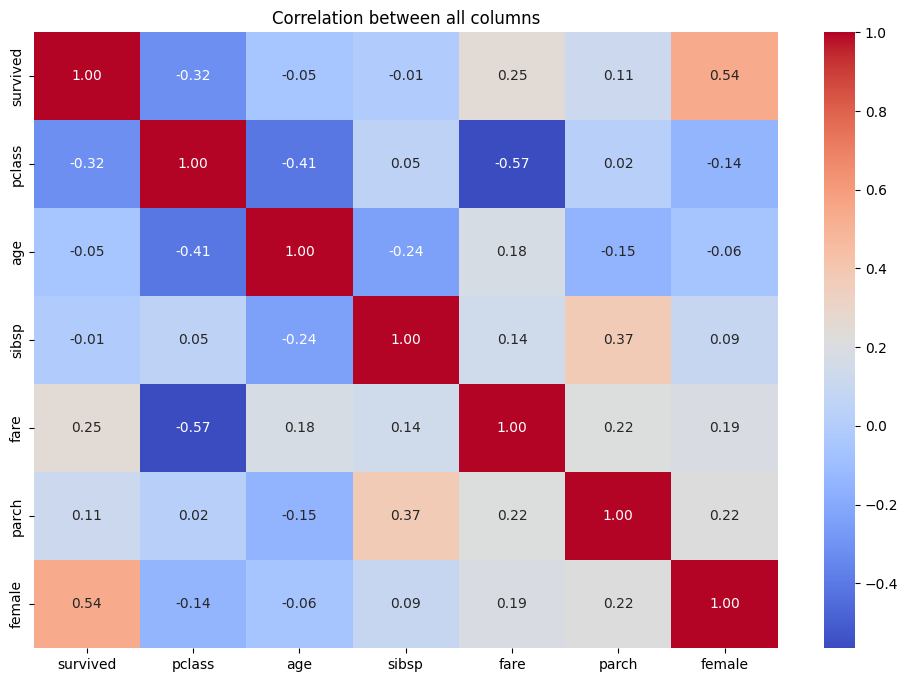

In [24]:

corr_matrix = titanic2[['survived','pclass','age','sibsp', 'fare', 'parch', 'female']].corr() # create the correlation matrix

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix,annot=True, fmt='.2f', cmap='coolwarm') #plotting it as a heatmap
plt.title('Correlation between all columns')

column_correlation = corr_matrix.abs().mean().sort_values(ascending=False) #list with the correlation mean
display('Mean Column Correlation:', column_correlation)

As seen in by the correlation, we've managed to choose the one with less correlation with other variables, therefore avoiding possible overlapping or noise that may be caused by too similar features between them (like fare and pclass)

## Same process as before but using a fifth feature

In [ ]:
titanic = pd.read_csv("../Data/Titanic Dataset.csv")
titanic = titanic[['survived','pclass', 'sex','age','sibsp',"parch"]].dropna()
dummies = pd.get_dummies(titanic['sex']).applymap(int) 

titanic = pd.concat([titanic, dummies.female], axis=1)
features = ['pclass', 'female','age','sibsp', "parch"]
target = 'survived'
Y = titanic[target].to_numpy(dtype = float )
X = titanic[features].to_numpy()

C:\Users\mauri\AppData\Local\Temp\ipykernel_21000\1823259837.py:3: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  dummies = pd.get_dummies(titanic['sex']).applymap(int)


In [30]:
training_results = [vectorized_result(y) for y in Y]
training_inputs = [np.reshape(x, (5, 1)) for x in X] #reshaped to 5 rows now since we have 5 input variables

In [31]:
rng = np.random.default_rng()
ix_example = np.arange(len(Y))
rng.shuffle(ix_example)     

In [ ]:
layers = [5,10,2] #input layer, hidden layer(s), output layer
#initiate weights
num_layers = len(layers)
# running a single epoch consisting of all training examples

# initiating bias and weighs
bias = []
Weight = []
for i, j in zip(layers,layers[1:]):
    bias.append(np.random.randn(j,1)) # a random bias with j rows and 1 col
    Weight.append(np.random.randn(j,i)) # a random Weight matrix with j rows and i cols
NUM_EPOCHS = 10
cost = []
eta = 0.1 # learn rate
for epoch in range(NUM_EPOCHS):
    for i in ix_example:
        x = training_inputs[i]
        y = training_results[i]

        # feedforward
        act = x
        act_list = [x] # store all activations layer-by-layer
        zs = [] # list to store all the z vectors, layer by layer
        for w, b in zip(Weight, bias):
            z = np.dot(w,act) + b
            zs.append(z)
            act = sigmoid(z)
            act_list.append(act)

        # get the gradients nabla_b and nabla_w for each layer based on the training examplea
        nabla_b, nabla_w = backpropagation(bias, Weight, num_layers, x, y)
        # update weights based on training example
        # update weights 
        Weight = [w-eta*nw for w, nw in zip(Weight, nabla_w)]
        # update biases
        bias = [b-eta*nb for b, nb in zip(bias, nabla_b)]
    y_preds = [forward_pass(Weight, bias, x) for x in training_inputs]
    correct_prop_test = evaluate(y_preds, training_results)/len(training_results)
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} — Accuracy: {correct_prop_test:.4f}")

Epoch 1/10 — Accuracy: 0.6214
Epoch 2/10 — Accuracy: 0.6224
Epoch 3/10 — Accuracy: 0.6214
Epoch 4/10 — Accuracy: 0.6214
Epoch 5/10 — Accuracy: 0.6214
Epoch 6/10 — Accuracy: 0.6224
Epoch 7/10 — Accuracy: 0.6224
Epoch 8/10 — Accuracy: 0.6224
Epoch 9/10 — Accuracy: 0.6224
Epoch 10/10 — Accuracy: 0.6224


In [33]:
y_preds = [forward_pass(Weight, bias, x) for x in training_inputs]

### Final Results

In [34]:
correct_prop_5 = evaluate(y_preds, training_results)/len(training_results)
correct_prop_5

np.float64(0.6223709369024857)

It turns out that the final accuracy of the network [5,10,2] is 0.623

## *Task 2b. Adapt the code so that you can use 5 input variables and add one variable of your* *choice. Did you perform better? What is the best layout of the network? (5p)*

In comparison, the 5 input model was the least accurate out of the three models seen until now (linear regression, [4,5,2] and [5,10,2]). We have various theories to why this might have been the case. In the case of variable choice, we feel that Parch was really the only sensible option to choose out of the dataset. For instance, columns like 'Body', 'Boat', 'Fare' are linked directly to the survival of the individual the same way that 'Name', 'Cabin', 'ticket' are unique values that wouldn't add correct weights or correlations. So, the only logical option is 'Parch'.

Nevertheless, even though we might have considered it the most adequate feature to include, the result could be due to the fact that we have so many rebundant information and correlation in the initial 4 input variables that the noise might have worsen the accuracy. For example, fare is directly correlated to pclass and could have created an issue there.

In terms of the number of neurons in the hidden layers, through trial and error that hasn't been included in this notebook because of its repetitiveness, we tried to include all numbers between 6 and 10, 20,100 and so on and found that 10 made the most sense as it balanced sufficient depth in the model to get good outputs and attribute weights with not as much noise, overfitting and other phenomena related to the excess of analysis, making the [5,10,2] configuration possibly the best we've encountered until now in this particular case (5 features).


## *Task 2c. Why do we have two output nodes? What happens if you just use one? Can you adapt a network with just one output node to this problem? (2p)*

It's no coincidence that we have two output nodes. This is because we match the amount of nodes to the amount of possible result, having set one node for survival and another node for non-survival that move between 0 and 1 and clearly show the result or error in each one.

We could adapt the amount of output nodes by using only one if we change the approach of the network. What we would do would be using a similar reasoning to the one the linear models use were, by adapting the weights to make them set over or under the line of regression. This would end up giving us the posibilities of survival for some concrete characteristics for each case.

## *Task 2d. Adapt the code so that it can run batches or mini batches. For an example, see solutions to Homework 3! (2p)*

## Adaptation of the code to run in batches:

The final step of this notebook (task) is to run the code in batches which is exactly what we are going to do next.

To do so, we've introduced the concept of "epochs" that we will reuse in task 3. An epoch is defined as a whole runthrough of all of the data that forms the training sample. For example, if the training data had 100 rows, running 2 epochs would be running the 100 rows twice. This is important to understand as it will be later work to run different samples of the training data of the same size to train the model.

For the sake of the adaptation of the code, we've decided to sample the training data in batches of 15 rows each and will use epochs of "size 50". This means that we will run different 15-row samples 50 times (50x15=750 which ends up being 75% of all the train data).

The procedure to see the weights is practically the same in terms of the code but now we can see how the accuracy of each epoch changes to finally form the total accuracy.



In [35]:
len(training_inputs) #see the dimension of the training data to get 75% of the training data

1046

In [36]:
layers = [5,10,2] #input layer, hidden layer(s), output layer
#initiate weights
num_layers = len(layers)


# initiating bias and weighs
bias = []
Weight = []
for i, j in zip(layers,layers[1:]):
    bias.append(np.random.randn(j,1)) # a random bias with j rows and 1 col
    Weight.append(np.random.randn(j,i)) # a random Weight matrix with j rows and i cols
    
NUM_EPOCHS = 50 # 50x15 = 750 around 75% of training data 
cost = []
eta = 0.1 # learn rate
for epoch in range(NUM_EPOCHS):
    sample_idx = np.random.choice(len(training_inputs), size=15, replace=False)
    for i in sample_idx:
        x = training_inputs[i]
        y = training_results[i]

        # feedforward
        act = x
        act_list = [x] # store all activations layer-by-layer
        zs = [] # list to store all the z vectors, layer by layer
        for w, b in zip(Weight, bias):
            z = np.dot(w,act) + b
            zs.append(z)
            act = sigmoid(z)
            act_list.append(act)

        # get the gradients nabla_b and nabla_w for each layer based on the training example
        nabla_b, nabla_w = backpropagation(bias, Weight, num_layers, x, y)
        # update weights based on training example
        # update weights 
        Weight = [w-eta*nw for w, nw in zip(Weight, nabla_w)]
        # update biases
        bias = [b-eta*nb for b, nb in zip(bias, nabla_b)]
    y_preds = [forward_pass(Weight, bias, x) for x in training_inputs]
    correct_prop_test = evaluate(y_preds, training_results)/len(training_results)
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} — Accuracy: {correct_prop_test:.4f}")

Epoch 1/50 — Accuracy: 0.4073
Epoch 2/50 — Accuracy: 0.4073
Epoch 3/50 — Accuracy: 0.4063
Epoch 4/50 — Accuracy: 0.4044
Epoch 5/50 — Accuracy: 0.4044
Epoch 6/50 — Accuracy: 0.4044
Epoch 7/50 — Accuracy: 0.4034
Epoch 8/50 — Accuracy: 0.4140
Epoch 9/50 — Accuracy: 0.5927
Epoch 10/50 — Accuracy: 0.5927
Epoch 11/50 — Accuracy: 0.5927
Epoch 12/50 — Accuracy: 0.6004
Epoch 13/50 — Accuracy: 0.5937
Epoch 14/50 — Accuracy: 0.6023
Epoch 15/50 — Accuracy: 0.4054
Epoch 16/50 — Accuracy: 0.5956
Epoch 17/50 — Accuracy: 0.4226
Epoch 18/50 — Accuracy: 0.5966
Epoch 19/50 — Accuracy: 0.5927
Epoch 20/50 — Accuracy: 0.5927
Epoch 21/50 — Accuracy: 0.5927
Epoch 22/50 — Accuracy: 0.5927
Epoch 23/50 — Accuracy: 0.5946
Epoch 24/50 — Accuracy: 0.5966
Epoch 25/50 — Accuracy: 0.5956
Epoch 26/50 — Accuracy: 0.5956
Epoch 27/50 — Accuracy: 0.5966
Epoch 28/50 — Accuracy: 0.6004
Epoch 29/50 — Accuracy: 0.5937
Epoch 30/50 — Accuracy: 0.5927
Epoch 31/50 — Accuracy: 0.5946
Epoch 32/50 — Accuracy: 0.4044
Epoch 33/50 — Acc

## Final Conclusions on the model.

We can finally conclude that by running mini batches, we decrease the accuracy of the model. This can be due to the learning rate being too big for the last epochs (thing we will also mention in task 3) but after trying by trial and error, this rate is the one that seems the most optimal by balancing fast/agile learning with minimizing the risk of divergence or over corrections in the final epochs (which still happen regardless).

In [37]:
print("4 colums:",correct_prop_4,"\n","5 colums:", correct_prop_5, "\n","SCkit learn linear model:", base_model_accuracy,"\n","Baseline:",1-sum(Y)/len(Y))

4 colums: 0.7829827915869981 
 5 colums: 0.6223709369024857 
 SCkit learn linear model: 0.7238095238095238 
 Baseline: 0.5917782026768643
